### Setup and Libraries


In [14]:
!pip install -q opacus

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from opacus import PrivacyEngine
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

### Data Preparation


In [15]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset_full = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_subset_indices = list(range(20000))
train_subset = Subset(train_dataset_full, train_subset_indices)

train_loader = DataLoader(train_subset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

### Model Definition & Utility Functions


In [16]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1)
        self.gn1 = nn.GroupNorm(4, 16)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1)
        self.gn2 = nn.GroupNorm(4, 32)
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = F.relu(self.gn1(self.conv1(x)))
        x = F.relu(self.gn2(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)
        x = self.fc(x)
        return x

def train_epoch(model, loader, optimizer):
    model.train()
    for images, targets in loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = F.cross_entropy(outputs, targets)
        loss.backward()
        optimizer.step()

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, targets in loader:
            outputs = model(images)
            predictions = outputs.argmax(dim=1, keepdim=True)
            correct += predictions.eq(targets.view_as(predictions)).sum().item()
            total += targets.size(0)
    return (correct / total) * 100

def get_mean_confidence(model, loader):
    model.eval()
    confidences = []
    with torch.no_grad():
        for images, _ in loader:
            outputs = model(images)
            probabilities = F.softmax(outputs, dim=1)
            max_probs, _ = torch.max(probabilities, dim=1)
            confidences.extend(max_probs.tolist())
    return np.mean(confidences)

### Task 1: Train Non-Private Baseline Model


In [17]:
baseline_model = SimpleCNN()
baseline_optimizer = optim.SGD(baseline_model.parameters(), lr=0.1, momentum=0.9)

for epoch in range(3):
    train_epoch(baseline_model, train_loader, baseline_optimizer)

baseline_acc = evaluate(baseline_model, test_loader)
print(f"Baseline (no DP) : test accuracy {baseline_acc:.1f} %")

Baseline (no DP) : test accuracy 96.2 %


### Task 2: Train DP Models for Target Epsilon = 10, 5, and 1


In [18]:
target_epsilons = [10.0, 5.0, 1.0]
dp_results = []
models_store = {}

for eps in target_epsilons:
    model_dp = SimpleCNN()
    optimizer_dp = optim.SGD(model_dp.parameters(), lr=0.1, momentum=0.9)

    engine = PrivacyEngine()
    model_dp, optimizer_dp, loader_dp = engine.make_private_with_epsilon(
        module=model_dp,
        optimizer=optimizer_dp,
        data_loader=train_loader,
        target_epsilon=eps,
        target_delta=1e-5,
        epochs=3,
        max_grad_norm=1.0
    )

    for epoch in range(3):
        train_epoch(model_dp, loader_dp, optimizer_dp)

    acc = evaluate(model_dp, test_loader)
    spent = engine.get_epsilon(1e-5)
    dp_results.append({"target": eps, "acc": acc, "spent": spent})
    models_store[eps] = model_dp

print("TARGET_EPS   DELTA    CLIP(C)   EPOCHS   TEST_ACC   EPS_SPENT")
print("-------------------------------------------------------------")
for res in dp_results:
    print(f"   {res['target']:<10.1f} 1e-05     1.0        3       {res['acc']:.1f} %      {res['spent']:.2f}")
print("-------------------------------------------------------------")

eps_1_acc = next(res["acc"] for res in dp_results if res["target"] == 1.0)
acc_cost = eps_1_acc - baseline_acc
print(f"\nAccuracy cost of strongest privacy (eps = 1) : {acc_cost:.1f} %")

/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/tmp/ipykernel_1671/1186356550.py:23: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


TARGET_EPS   DELTA    CLIP(C)   EPOCHS   TEST_ACC   EPS_SPENT
-------------------------------------------------------------
   10.0       1e-05     1.0        3       93.5 %      9.99
   5.0        1e-05     1.0        3       92.9 %      5.00
   1.0        1e-05     1.0        3       92.0 %      1.00
-------------------------------------------------------------

Accuracy cost of strongest privacy (eps = 1) : -4.1 %


### Task 5 (Part A): Plot Test Accuracy vs. Epsilon


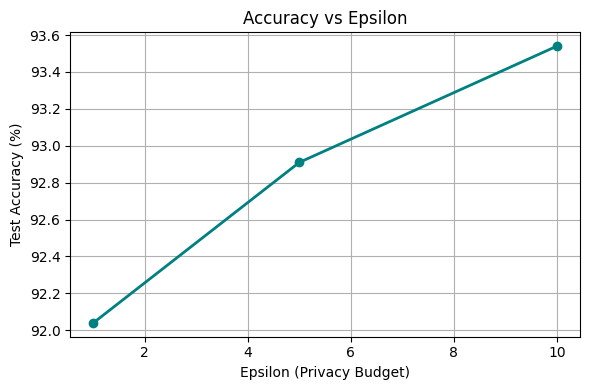

In [19]:
eps_plot_values = [10.0, 5.0, 1.0]
acc_plot_values = [next(res["acc"] for res in dp_results if res["target"] == e) for e in eps_plot_values]

plt.figure(figsize=(6, 4))
plt.plot(eps_plot_values, acc_plot_values, marker='o', color='teal', linewidth=2)
plt.title("Accuracy vs Epsilon")
plt.xlabel("Epsilon (Privacy Budget)")
plt.ylabel("Test Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png")
plt.show()

### Task 3: Train private model with fixed noise multiplier


In [20]:
model_fixed = SimpleCNN()
optimizer_fixed = optim.SGD(model_fixed.parameters(), lr=0.1, momentum=0.9)
engine_fixed = PrivacyEngine()

model_fixed, optimizer_fixed, loader_fixed = engine_fixed.make_private(
    module=model_fixed,
    optimizer=optimizer_fixed,
    data_loader=train_loader,
    noise_multiplier=1.1,
    max_grad_norm=1.0
)

fixed_epsilons = []
print("FIXED noise_multiplier = 1.1")
print("EPOCH   EPSILON_SPENT")
print("---------------------")
for epoch in range(1, 4):
    train_epoch(model_fixed, loader_fixed, optimizer_fixed)
    spent = engine_fixed.get_epsilon(1e-5)
    fixed_epsilons.append(spent)
    print(f"  {epoch}         {spent:.2f}")
print("---------------------")

/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/tmp/ipykernel_1671/1186356550.py:23: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


FIXED noise_multiplier = 1.1
EPOCH   EPSILON_SPENT
---------------------
  1         0.66
  2         0.85
  3         1.01
---------------------


### Task 5 (Part B): Plot Epsilon Spent vs. Epoch


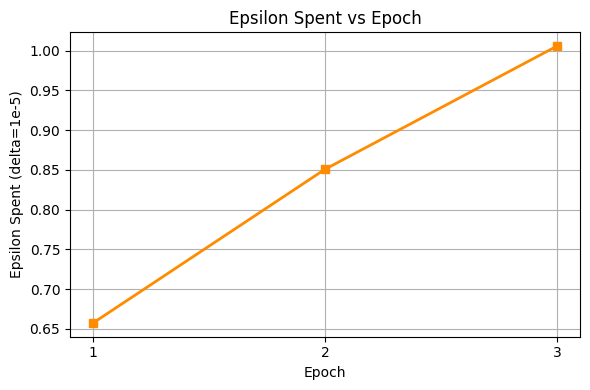

In [21]:
plt.figure(figsize=(6, 4))
plt.plot([1, 2, 3], fixed_epsilons, marker='s', color='darkorange', linewidth=2)
plt.title("Epsilon Spent vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Epsilon Spent (delta=1e-5)")
plt.xticks([1, 2, 3])
plt.grid(True)
plt.tight_layout()
plt.savefig("epsilon_vs_epoch.png")
plt.show()

In [22]:
train_eval_loader = DataLoader(train_subset, batch_size=256, shuffle=False)

base_train_conf = get_mean_confidence(baseline_model, train_eval_loader)
base_test_conf = get_mean_confidence(baseline_model, test_loader)
base_gap = base_train_conf - base_test_conf

eps_1_model = models_store[1.0]
dp_train_conf = get_mean_confidence(eps_1_model, train_eval_loader)
dp_test_conf = get_mean_confidence(eps_1_model, test_loader)
dp_gap = dp_train_conf - dp_test_conf

print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print("MODEL        TRAIN    TEST     GAP")
print("-----------------------------------")
print(f"Baseline     {base_train_conf:.3f}    {base_test_conf:.3f}    {base_gap:.3f}")
print(f"DP (eps=1)   {dp_train_conf:.3f}    {dp_test_conf:.3f}    {dp_gap:.3f}")
print("-----------------------------------")

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL        TRAIN    TEST     GAP
-----------------------------------
Baseline     0.951    0.951    -0.001
DP (eps=1)   0.958    0.959    -0.001
-----------------------------------
